In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

Saving rose.jpg to rose.jpg


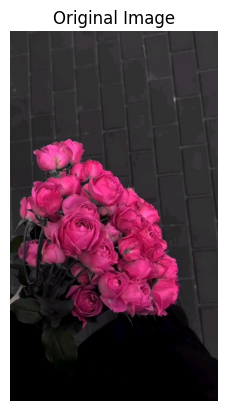

In [2]:
uploaded = files.upload()

if not uploaded:
    raise ValueError("Please upload an image.")

filename = next(iter(uploaded.keys()))

image_bgr = cv2.imread(filename)

if image_bgr is None:
    raise ValueError("Invalid image file.")

image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

plt.imshow(image)
plt.title("Original Image")
plt.axis("off")
plt.show()

In [3]:
print("Image Name:", filename)
print("Image Shape:", image.shape)
print("Height:", image.shape[0])
print("Width:", image.shape[1])
print("Channels:", image.shape[2])
print("Data Type:", image.dtype)
print("Total Pixels:", image.shape[0] * image.shape[1])

Image Name: rose.jpg
Image Shape: (1280, 720, 3)
Height: 1280
Width: 720
Channels: 3
Data Type: uint8
Total Pixels: 921600


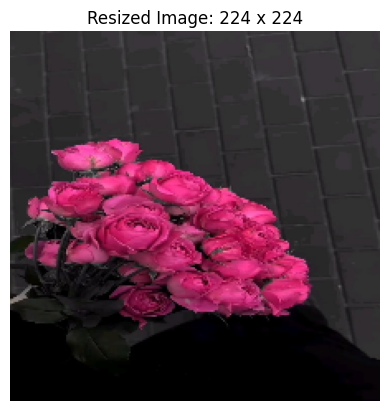

In [4]:
resized = cv2.resize(image, (224, 224))

plt.imshow(resized)
plt.title("Resized Image: 224 x 224")
plt.axis("off")
plt.show()

Minimum Value: 0.0
Maximum Value: 1.0


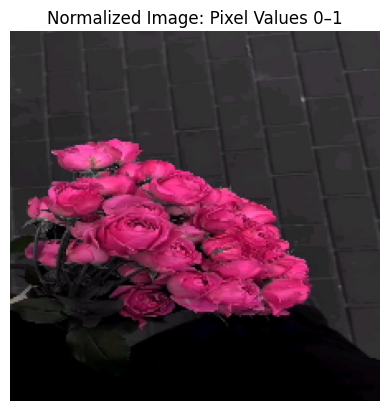

In [5]:
normalized = resized.astype(np.float32) / 255.0

print("Minimum Value:", normalized.min())
print("Maximum Value:", normalized.max())

plt.imshow(normalized)
plt.title("Normalized Image: Pixel Values 0–1")
plt.axis("off")
plt.show()

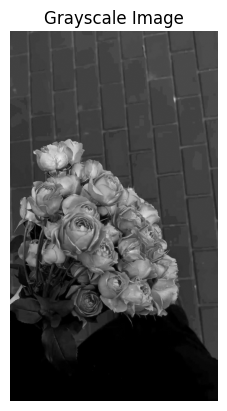

In [6]:
grayscale = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

plt.imshow(grayscale, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")
plt.show()

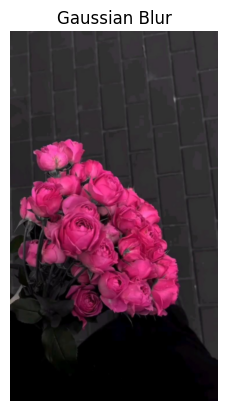

In [7]:
blurred = cv2.GaussianBlur(image, (5, 5), 0)

plt.imshow(blurred)
plt.title("Gaussian Blur")
plt.axis("off")
plt.show()

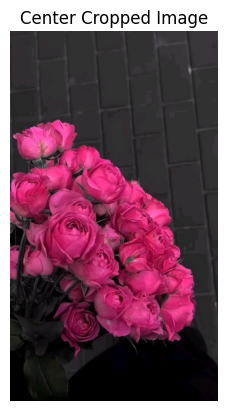

In [8]:
height, width = image.shape[:2]

crop_height = int(height * 0.80)
crop_width = int(width * 0.80)

start_y = (height - crop_height) // 2
start_x = (width - crop_width) // 2

cropped = image[
    start_y:start_y + crop_height,
    start_x:start_x + crop_width
]

plt.imshow(cropped)
plt.title("Center Cropped Image")
plt.axis("off")
plt.show()

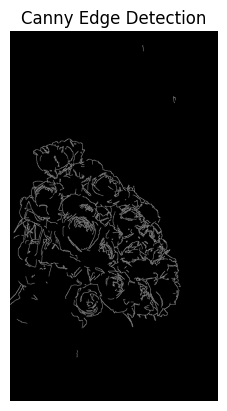

In [9]:
edges = cv2.Canny(grayscale, 100, 200)

plt.imshow(edges, cmap="gray")
plt.title("Canny Edge Detection")
plt.axis("off")
plt.show()

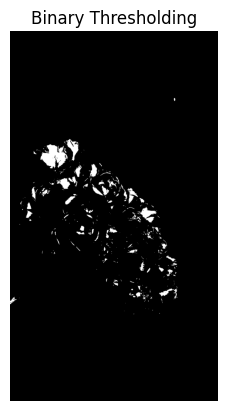

In [10]:
_, thresholded = cv2.threshold(
    grayscale, 127, 255, cv2.THRESH_BINARY
)

plt.imshow(thresholded, cmap="gray")
plt.title("Binary Thresholding")
plt.axis("off")
plt.show()

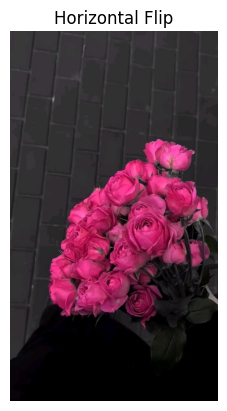

In [11]:
flipped = cv2.flip(image, 1)

plt.imshow(flipped)
plt.title("Horizontal Flip")
plt.axis("off")
plt.show()

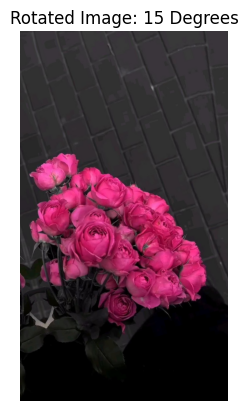

In [12]:
height, width = image.shape[:2]
center = (width // 2, height // 2)

rotation_matrix = cv2.getRotationMatrix2D(center, 15, 1.0)

rotated = cv2.warpAffine(
    image,
    rotation_matrix,
    (width, height),
    borderMode=cv2.BORDER_REFLECT
)

plt.imshow(rotated)
plt.title("Rotated Image: 15 Degrees")
plt.axis("off")
plt.show()

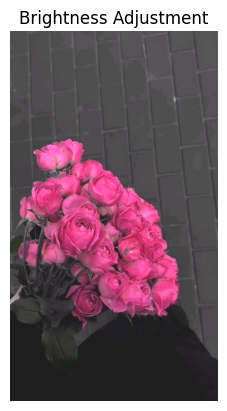

In [13]:
brightened = cv2.convertScaleAbs(image, alpha=1.0, beta=30)

plt.imshow(brightened)
plt.title("Brightness Adjustment")
plt.axis("off")
plt.show()

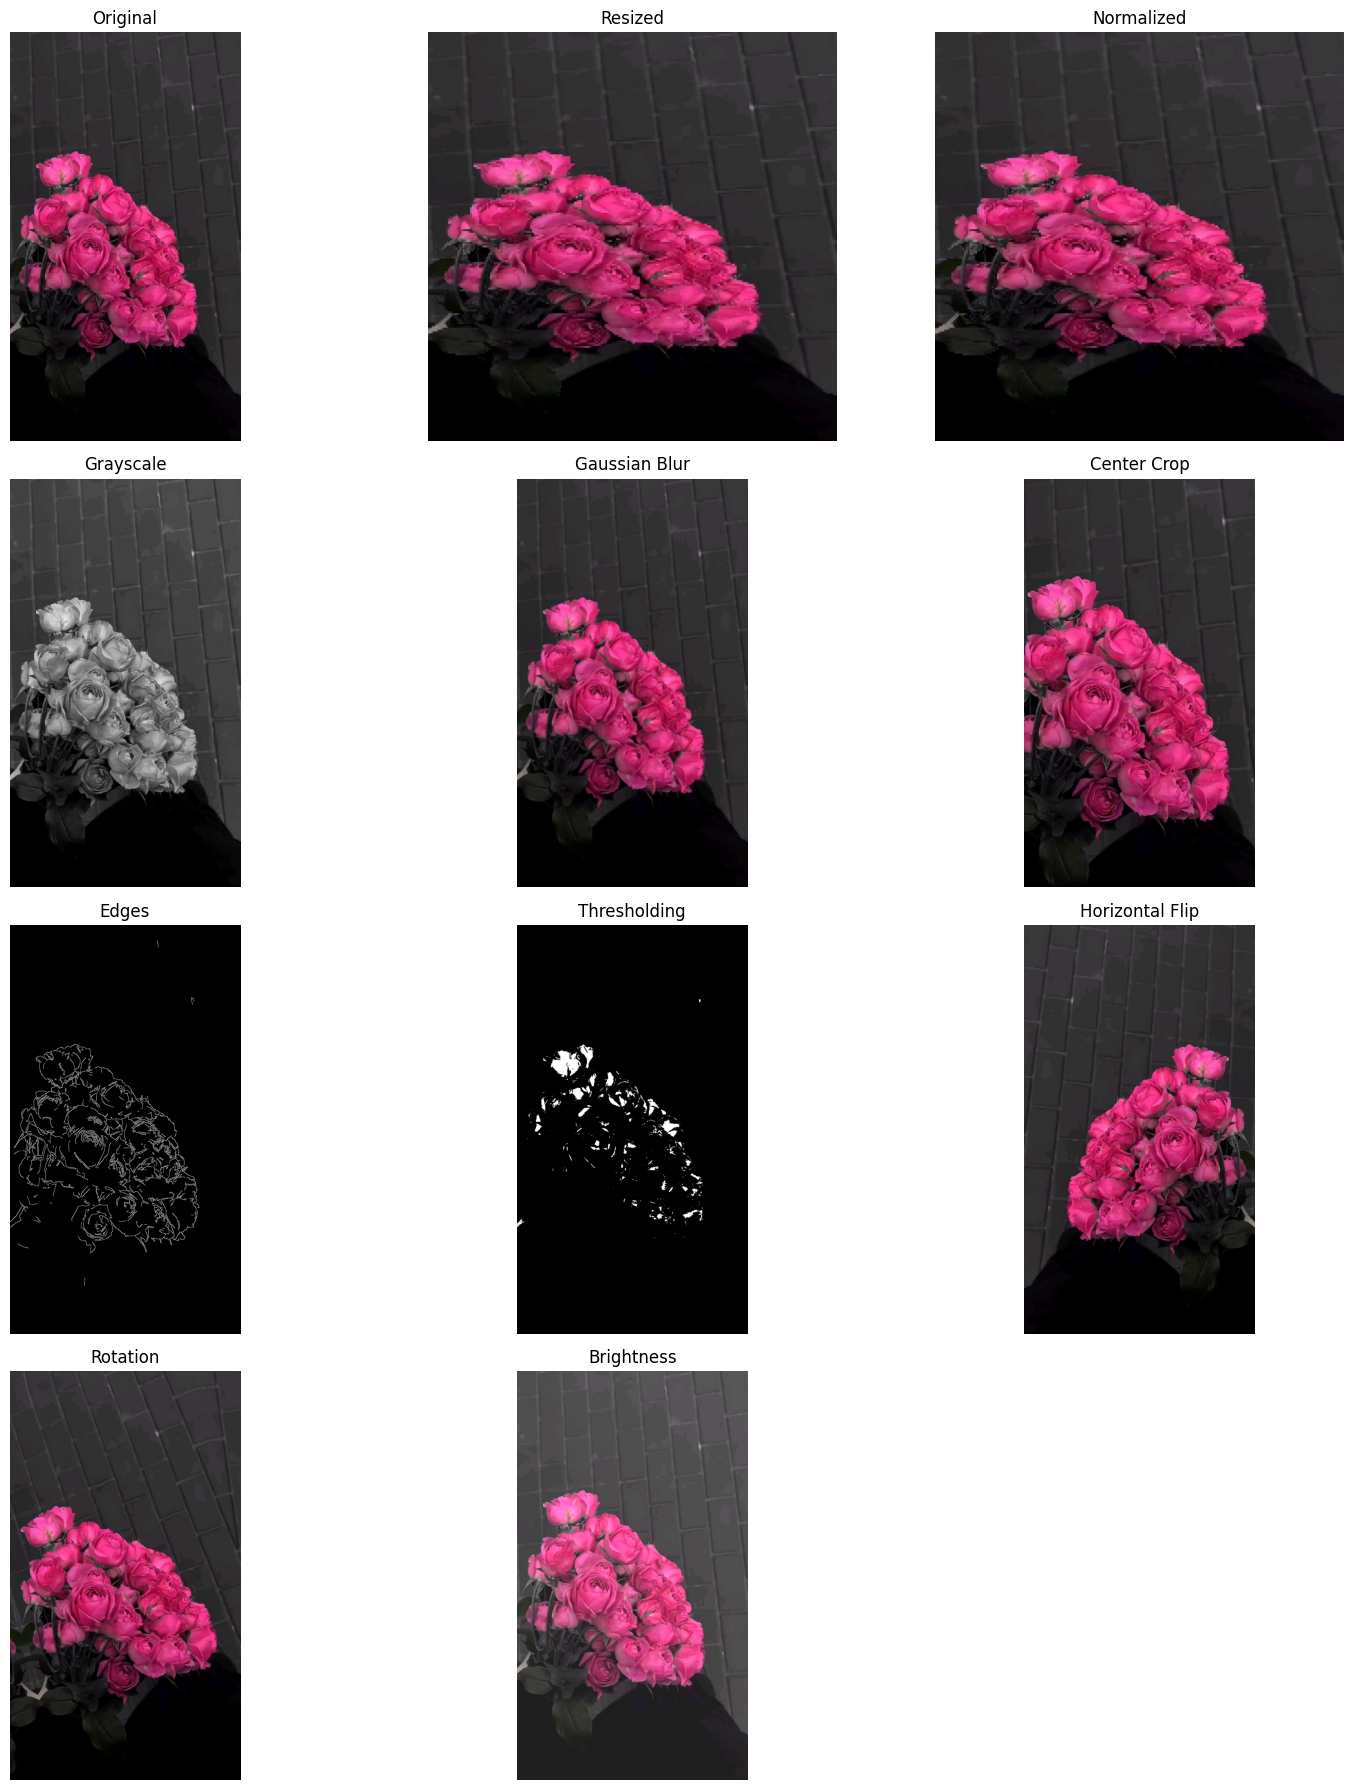

In [14]:
images = [
    ("Original", image),
    ("Resized", resized),
    ("Normalized", normalized),
    ("Grayscale", grayscale),
    ("Gaussian Blur", blurred),
    ("Center Crop", cropped),
    ("Edges", edges),
    ("Thresholding", thresholded),
    ("Horizontal Flip", flipped),
    ("Rotation", rotated),
    ("Brightness", brightened)
]

plt.figure(figsize=(16, 18))

for i, (title, img) in enumerate(images, 1):
    plt.subplot(4, 3, i)

    if img.ndim == 2:
        plt.imshow(img, cmap="gray")
    else:
        plt.imshow(img)

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
cv2.imwrite("resized.jpg", cv2.cvtColor(resized, cv2.COLOR_RGB2BGR))
cv2.imwrite("blurred.jpg", cv2.cvtColor(blurred, cv2.COLOR_RGB2BGR))
cv2.imwrite("cropped.jpg", cv2.cvtColor(cropped, cv2.COLOR_RGB2BGR))
cv2.imwrite("grayscale.jpg", grayscale)
cv2.imwrite("edges.jpg", edges)
cv2.imwrite("thresholded.jpg", thresholded)
cv2.imwrite("flipped.jpg", cv2.cvtColor(flipped, cv2.COLOR_RGB2BGR))
cv2.imwrite("rotated.jpg", cv2.cvtColor(rotated, cv2.COLOR_RGB2BGR))
cv2.imwrite("brightened.jpg", cv2.cvtColor(brightened, cv2.COLOR_RGB2BGR))

print("All processed images saved successfully!")

files.download("edges.jpg")

All processed images saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>